# A. Problem


## A.1 Rumusan Masalah

Email dan pesan digital dapat berisi komunikasi normal (*Ham*), promosi atau pesan tidak diinginkan (*Spam*), serta pesan penipuan yang berupaya memancing tindakan atau informasi sensitif (*Phish*). Permasalahan penelitian ini adalah membangun model *Classical Machine Learning* yang dapat mengklasifikasikan teks pesan secara otomatis ke dalam tiga kelas tersebut. Fokusnya adalah membantu penyaringan dan peninjauan pesan berdasarkan isi teks, bukan sekadar mengejar nilai akurasi tertinggi.

Penelitian ini tidak menggunakan Deep Learning pada tahap baseline.

## A.2 Tujuan

Tujuan tahap ini adalah:

1. membangun kerangka klasifikasi teks otomatis untuk kelas Ham, Phish, dan Spam;
2. memahami dan menyiapkan dataset sebelum pelatihan;
3. membentuk baseline sebagai pembanding untuk metode yang diusulkan dalam penelitian ini pada tahap berikutnya; dan
4. mengevaluasi sejauh mana baseline dapat mendeteksi ketiga jenis pesan tersebut.

## A.3 Target

Target prediksi adalah kolom `label` dengan pemetaan berikut:

| Nilai | Kelas |
| ---: | --- |
| 0 | Ham |
| 1 | Phish |
| 2 | Spam |

Setiap pesan memiliki tepat satu label, sehingga target bersifat kategorikal dan *single-label*.

## A.4 Fitur

Fitur mentah pada dataset adalah `text`, yaitu isi email atau pesan. Dataset asli belum memiliki ribuan fitur numerik. Pada tahap modeling berikutnya, `text` akan diubah menjadi representasi numerik TF-IDF. Representasi TF-IDF tersebut adalah fitur yang dibentuk oleh proses modeling, bukan kolom asli dataset.

## A.5 Jenis Masalah

Masalah ini diklasifikasikan sebagai:

**Supervised Learning** → **Text Classification** → **Multiclass Single-Label Classification**

Data berlabel digunakan untuk belajar membedakan tiga kelas, dan setiap pesan hanya dapat berada pada satu kelas.

# B. Dataset

## B.1 Sumber Dataset

Dataset berasal dari Hugging Face: [`locuoco/the-biggest-spam-ham-phish-email-dataset-300000`](https://huggingface.co/datasets/locuoco/the-biggest-spam-ham-phish-email-dataset-300000). Dataset dimuat dengan `datasets.load_dataset(...)` menggunakan split `train`. Nama `train` berasal dari penyedia dataset; pembagian data training dan testing untuk penelitian ini dilakukan pada bagian D.2.

Sel berikut memuat dataset dan menampilkan nama split, jumlah baris, dan nama kolom.

In [1]:
# Pemuatan dataset yang kompatibel dengan Google Colab.
# Jalankan sekali pada runtime baru; paket hanya dipasang bila belum tersedia.
import sys
import subprocess

try:
    from datasets import load_dataset
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'datasets'])
    from datasets import load_dataset

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

DATASET_NAME = 'locuoco/the-biggest-spam-ham-phish-email-dataset-300000'
LABEL_NAMES = {0: 'Ham', 1: 'Phish', 2: 'Spam'}
VALID_LABELS = set(LABEL_NAMES)

dataset = load_dataset(DATASET_NAME, split='train')
raw_df = dataset.to_pandas()

print(f'Sumber dataset : {DATASET_NAME}')
print(f'Split          : train')
print(f'Jumlah baris   : {len(raw_df):,}')
print(f'Kolom          : {raw_df.columns.tolist()}')

README.md:   0%|          | 0.00/990 [00:00<?, ?B/s]

df.csv: reconstructing file:   0%|          |  0.00B /  631MB            

df.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/365448 [00:00<?, ? examples/s]

Sumber dataset : locuoco/the-biggest-spam-ham-phish-email-dataset-300000
Split          : train
Jumlah baris   : 365,448
Kolom          : ['label', 'text']


## B.2 Jumlah Data

Sel berikut menghitung jumlah baris yang dimuat dan membandingkannya dengan jumlah baris dataset, yaitu 365.448 baris. Jika jumlahnya berbeda, versi dataset yang dimuat perlu diperiksa sebelum analisis dilanjutkan.

In [2]:
EXPECTED_RAW_ROWS = 365_448

row_check = pd.DataFrame({
    'metrik': ['Jumlah baris yang dimuat', 'Jumlah baris referensi dataset'],
    'nilai': [len(raw_df), EXPECTED_RAW_ROWS]
})
row_check['sesuai_referensi'] = row_check['nilai'].eq(EXPECTED_RAW_ROWS)
display(row_check)

if len(raw_df) != EXPECTED_RAW_ROWS:
    print('Perbedaan jumlah baris terdeteksi. Periksa versi dataset atau split yang dimuat sebelum melanjutkan.')
else:
    print('Jumlah baris sesuai dengan referensi dataset.')

,metrik,nilai,sesuai_referensi
0,Jumlah baris yang dimuat,365448,True
1,Jumlah baris referensi dataset,365448,True


Jumlah baris sesuai dengan referensi dataset.


## B.3 Fitur Dataset

Dataset memiliki dua kolom: `text` berisi isi pesan dan `label` berisi kelas pesan. Sel berikut menampilkan ukuran data, tipe data setiap kolom, dan lima baris pertama.

In [3]:
required_columns = {'text', 'label'}
missing_columns = required_columns.difference(raw_df.columns)
if missing_columns:
    raise ValueError(f'Kolom wajib tidak ditemukan: {sorted(missing_columns)}')

print('Shape dataframe:', raw_df.shape)
display(raw_df.dtypes.rename('dtype').to_frame())
display(raw_df.head())

Shape dataframe: (365448, 2)


,dtype
label,int64
text,object


,label,text
0,0,wrong bill grace i ' ll forward original messa...
1,0,i have continued the hilcorp old ocean deal da...
2,0,several related issues have resulted in an inc...
3,0,one year rate for this one will be escapenumbe...
4,0,attached is the weekly deal report for escapen...


## B.4 Target Dataset

Sel berikut menghitung jumlah dan persentase pesan pada setiap kelas, lalu memeriksa apakah ada label di luar 0, 1, dan 2. Jika jumlah pesan antar kelas tidak seimbang, accuracy saja tidak cukup untuk menilai model.

,jumlah,persentase
label,,
Ham,168455,46.0955
Phish,42845,11.7240
Spam,154148,42.1806


Label tidak valid: 0


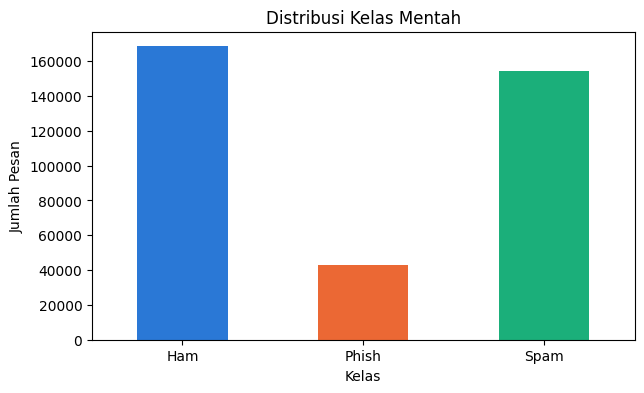

In [4]:
invalid_label_mask = raw_df['label'].notna() & ~raw_df['label'].isin(VALID_LABELS)
raw_class_distribution = (
    raw_df['label']
    .value_counts(dropna=False)
    .sort_index()
    .rename(index=LABEL_NAMES)
    .rename('jumlah')
    .to_frame()
)
raw_class_distribution['persentase'] = (
    raw_class_distribution['jumlah'] / len(raw_df) * 100
).round(4)

display(raw_class_distribution)
print(f'Label tidak valid: {invalid_label_mask.sum():,}')

ax = raw_class_distribution.loc[['Ham', 'Phish', 'Spam'], 'jumlah'].plot(
    kind='bar', figsize=(7, 4), color=['#2a78d6', '#eb6834', '#1baf7a']
)
ax.set_title('Distribusi Kelas Mentah')
ax.set_xlabel('Kelas')
ax.set_ylabel('Jumlah Pesan')
plt.xticks(rotation=0)
plt.show()

## B.5 Kualitas Data

Sel pertama berikut memeriksa kualitas data dari lima aspek:

1. teks yang kosong (*missing value*) atau hanya berisi spasi;
2. label yang tidak valid;
3. baris dan teks yang muncul lebih dari sekali (duplikat);
4. panjang teks, termasuk pesan yang sangat panjang;
5. teks yang mengandung karakter non-ASCII.

Karakter non-ASCII adalah karakter di luar huruf Latin dasar, angka, dan tanda baca standar. Karakter ini belum tentu menandakan teks yang rusak atau berbahasa lain, tetapi menunjukkan teks yang perlu diperiksa. Halaman dataset menyebut bahasa Inggris, tetapi sebagian contoh teks berbahasa lain.

Sel kedua menampilkan teks yang sama tetapi memiliki label berbeda.

In [5]:
raw_text = raw_df['text']
missing_text_mask = raw_text.isna()
missing_label_mask = raw_df['label'].isna()
whitespace_only_mask = (
    raw_text.notna()
    & raw_text.astype(str).str.fullmatch(r'\s*', na=False)
)

quality_issues = pd.DataFrame({
    'masalah': [
        'Missing text',
        'Missing label',
        'Teks whitespace-only non-missing',
        'Label tidak valid',
        'Duplikat baris mentah di luar kemunculan pertama',
        'Duplikat text mentah di luar kemunculan pertama'
    ],
    'jumlah': [
        int(missing_text_mask.sum()),
        int(missing_label_mask.sum()),
        int(whitespace_only_mask.sum()),
        int(invalid_label_mask.sum()),
        int(raw_df.duplicated(keep='first').sum()),
        int(raw_text.duplicated(keep='first').sum())
    ]
})
display(quality_issues)

text_for_length = raw_text.fillna('').astype(str)
text_length = text_for_length.str.len()
display(text_length.describe(percentiles=[0.50, 0.90, 0.95, 0.99, 0.999]).to_frame('panjang_karakter'))

longest_examples = raw_df.assign(panjang_karakter=text_length).nlargest(5, 'panjang_karakter')[['label', 'panjang_karakter', 'text']].copy()
longest_examples['text'] = longest_examples['text'].fillna('').astype(str).str.replace(r'\s+', ' ', regex=True).str.slice(0, 180)
display(longest_examples.rename(columns={'label': 'label_asli', 'text': 'cuplikan_text'}))

non_ascii_mask = text_for_length.str.contains(r'[^\x00-\x7F]', regex=True, na=False)
non_ascii_examples = raw_df.loc[non_ascii_mask, ['label', 'text']].head(5).copy()
non_ascii_examples['text'] = non_ascii_examples['text'].fillna('').astype(str).str.replace(r'\s+', ' ', regex=True).str.slice(0, 180)
print(f'Baris dengan karakter non-ASCII: {non_ascii_mask.sum():,}')
display(non_ascii_examples.rename(columns={'label': 'label_asli', 'text': 'cuplikan_text'}))

,masalah,jumlah
0,Missing text,2
1,Missing label,0
2,Teks whitespace-only non-missing,1
3,Label tidak valid,0
4,Duplikat baris mentah di luar kemunculan pertama,84490
5,Duplikat text mentah di luar kemunculan pertama,84498


,panjang_karakter
count,3.654480e+05
mean,1.703693e+03
std,2.223080e+04
min,0.000000e+00
50%,7.630000e+02
90%,3.323000e+03
95%,5.163000e+03
99%,1.266000e+04
99.9%,5.445642e+04
max,1.151031e+07


,label_asli,panjang_karakter,cuplikan_text
174933,0,11510306,bodylabel 0subject great parttime summer job d...
170031,1,4279526,mail system internal data mailerdaemonmonkeyor...
38973,0,3140726,i have just begun work with dmdx and am having...
41029,0,1751482,by mescapenumber grp scd yahoo com with qmqp e...
40194,0,1312255,telecom digest wed escapenumber nov escapenumb...


Baris dengan karakter non-ASCII: 33,387


,label_asli,cuplikan_text
4384,0,vince from the sound of the articles it appear...
14320,2,escapenumber escapenumber escapenumber escapen...
14325,2,from the desk of mr chu sengchen bank of china...
14327,2,southwestern medical soiutions inc swnm a deve...
14328,2,alguna vez pens tener control total de su pc c...


In [6]:
# Compare exact duplicate rows with duplicate texts.
raw_duplicate_rows = raw_df.duplicated(keep='first')
raw_duplicate_texts = raw_df.duplicated(subset=['text'], keep='first')

print("Duplikat baris mentah:", raw_duplicate_rows.sum())
print("Duplikat text mentah:", raw_duplicate_texts.sum())
print(
    "Selisih duplicate text yang bukan duplicate baris:",
    (raw_duplicate_texts & ~raw_duplicate_rows).sum()
)

# Rows whose text is repeated, but whose complete row is not identical.
text_only_duplicates = raw_df.loc[
    raw_duplicate_texts & ~raw_duplicate_rows,
    ['text', 'label']
].copy()

text_only_duplicates['text_preview'] = (
    text_only_duplicates['text']
    .fillna('')
    .astype(str)
    .str.replace(r'\s+', ' ', regex=True)
    .str.slice(0, 250)
)

display(text_only_duplicates[['label', 'text_preview']])

# Inspect every occurrence of the relevant repeated texts,
# including all labels assigned to each text.
texts_to_inspect = text_only_duplicates['text'].drop_duplicates()

duplicate_text_groups = (
    raw_df.loc[raw_df['text'].isin(texts_to_inspect), ['text', 'label']]
    .groupby('text')
    .agg(
        total_rows=('label', 'size'),
        unique_labels=('label', lambda values: sorted(values.unique().tolist())),
        label_count=('label', 'nunique')
    )
    .reset_index()
)

duplicate_text_groups['text_preview'] = (
    duplicate_text_groups['text']
    .fillna('')
    .astype(str)
    .str.replace(r'\s+', ' ', regex=True)
    .str.slice(0, 250)
)

display(
    duplicate_text_groups[
        ['total_rows', 'unique_labels', 'label_count', 'text_preview']
    ]
)

Duplikat baris mentah: 84490
Duplikat text mentah: 84498
Selisih duplicate text yang bukan duplicate baris: 8


,label,text_preview
28787,0,unsubscribe
42992,2,hi
221772,2,escapenumber
238983,2,energy industry professional the book energy d...
269988,2,want cheap watch http kst nepel com
320810,0,
325400,0,hi
336070,2,escapenumber escapenumber escapenumber


,total_rows,unique_labels,label_count,text_preview
0,2,"[0, 2]",2,energy industry professional the book energy d...
1,2,"[0, 2]",2,escapenumber
2,2,"[0, 2]",2,escapenumber escapenumber escapenumber
3,4,"[0, 2]",2,hi
4,2,"[0, 1]",2,hi
5,4,"[0, 2]",2,unsubscribe
6,2,"[1, 2]",2,want cheap watch http kst nepel com


## B.6 Eksplorasi Data (EDA)

EDA dilakukan pada data mentah sebelum preprocessing. Empat fitur numerik berikut dihitung hanya untuk memahami data dan tidak dipakai sebagai masukan model:

| Fitur | Cara menghitung |
| --- | --- |
| `char_count` | Jumlah karakter pada teks. |
| `word_count` | Jumlah kata, yaitu potongan teks yang dipisahkan spasi. |
| `link_token_count` | Jumlah kata `http`, `https`, atau `www`. |
| `special_char_count` | Jumlah karakter yang bukan huruf, angka, underscore, atau spasi. |

**Catatan tentang tautan.** Dataset tidak menyimpan tanda baca, sehingga tautan tertulis sebagai kata terpisah, misalnya `http www contoh com`. Karena itu, tautan dihitung dari kata `http`, `https`, dan `www`.

### B.6.1 Analisis Univariat

Sel berikut menampilkan statistik deskriptif keempat fitur dan mendeteksi pencilan `word_count` dengan metode IQR. Pencilan adalah pesan dengan jumlah kata di atas Q3 + 1,5 × IQR. Grafik membandingkan distribusi `word_count` pada skala asli dan setelah transformasi log(1 + x).

Statistik deskriptif fitur eksploratif (data mentah)


,char_count,word_count,link_token_count,special_char_count
count,365448.00,365448.00,365448.00,365448.00
mean,1703.69,262.15,1.31,18.54
std,22230.80,2937.08,13.30,213.53
min,0.00,0.00,0.00,0.00
25%,343.00,53.00,0.00,0.00
50%,763.00,125.00,0.00,1.00
75%,1737.00,268.00,1.00,6.00
99%,12660.00,1885.00,14.00,268.00
max,11510306.00,1585483.00,6678.00,109347.00


,ukuran,nilai
0,Q1,53.00
1,Q3,268.00
2,IQR,215.00
3,"Batas atas (Q3 + 1,5 IQR)",590.50
4,Jumlah pencilan,30385.00
5,Persentase pencilan,8.31
6,word_count maksimum,1585483.00


Pencilan per kelas:


,jumlah_pencilan
kelas,
Ham,18677
Phish,887
Spam,10821


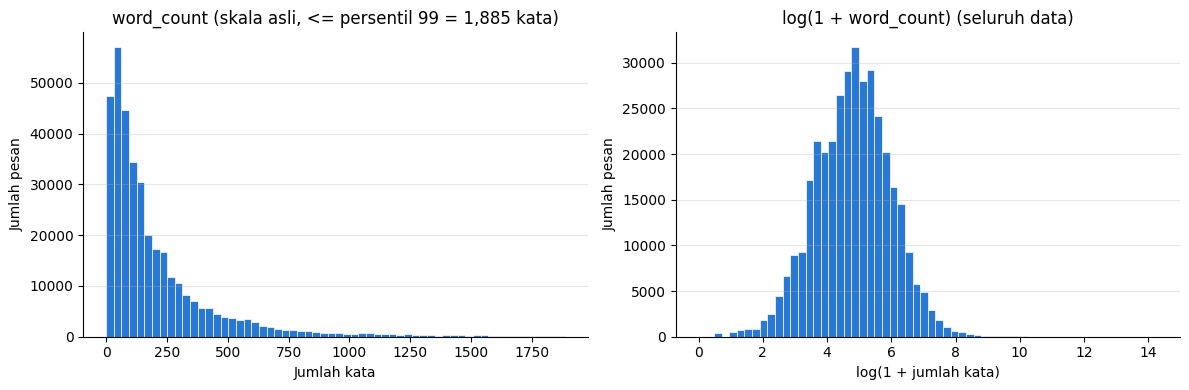

In [7]:
CLASS_ORDER = ['Ham', 'Phish', 'Spam']
CLASS_COLORS = {'Ham': '#2a78d6', 'Phish': '#eb6834', 'Spam': '#1baf7a'}

eda_text = raw_df['text'].fillna('').astype(str)
eda_df = pd.DataFrame({
    'kelas': raw_df['label'].map(LABEL_NAMES),
    'char_count': eda_text.str.len(),
    'word_count': eda_text.str.count(r'\S+'),
    'link_token_count': eda_text.str.count(r'\b(?:https?|www)\b'),
    'special_char_count': eda_text.str.count(r'[^\w\s]'),
})
EDA_FEATURES = ['char_count', 'word_count', 'link_token_count', 'special_char_count']

print('Statistik deskriptif fitur eksploratif (data mentah)')
display(eda_df[EDA_FEATURES].describe(percentiles=[0.25, 0.50, 0.75, 0.99]).round(2))

# Pencilan word_count dengan metode IQR
q1, q3 = eda_df['word_count'].quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
word_outlier_mask = eda_df['word_count'] > upper_fence
outlier_summary = pd.DataFrame({
    'ukuran': ['Q1', 'Q3', 'IQR', 'Batas atas (Q3 + 1,5 IQR)', 'Jumlah pencilan',
               'Persentase pencilan', 'word_count maksimum'],
    'nilai': [q1, q3, iqr, upper_fence, int(word_outlier_mask.sum()),
              round(word_outlier_mask.mean() * 100, 2), int(eda_df['word_count'].max())]
})
display(outlier_summary)
print('Pencilan per kelas:')
display(eda_df.loc[word_outlier_mask, 'kelas'].value_counts().reindex(CLASS_ORDER).rename('jumlah_pencilan').to_frame())

# Distribusi word_count: skala asli (dipotong di persentil 99 agar terbaca) vs log(1 + x)
p99_words = eda_df['word_count'].quantile(0.99)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(eda_df.loc[eda_df['word_count'] <= p99_words, 'word_count'], bins=60, color='#2a78d6', edgecolor='white', linewidth=0.5)
axes[0].set_title(f'word_count (skala asli, <= persentil 99 = {p99_words:,.0f} kata)')
axes[0].set_xlabel('Jumlah kata')
axes[0].set_ylabel('Jumlah pesan')
axes[1].hist(np.log1p(eda_df['word_count']), bins=60, color='#2a78d6', edgecolor='white', linewidth=0.5)
axes[1].set_title('log(1 + word_count) (seluruh data)')
axes[1].set_xlabel('log(1 + jumlah kata)')
axes[1].set_ylabel('Jumlah pesan')
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### B.6.2 Analisis Bivariat

Sel berikut membandingkan keempat fitur antar kelas. Median dipakai sebagai ukuran utama karena beberapa pesan yang sangat panjang dapat menaikkan rata-rata. Boxplot memakai skala log(1 + jumlah kata) dan tidak menampilkan titik pencilan agar kotak tetap terbaca.

,jumlah_pesan,median_char,median_word,mean_word,median_special_char,persen_ada_token_tautan
kelas,,,,,,
Ham,168455,986.0,161.0,346.26,2.0,33.54
Phish,42845,391.0,55.0,121.35,0.0,11.75
Spam,154148,679.0,110.0,209.37,1.0,44.76


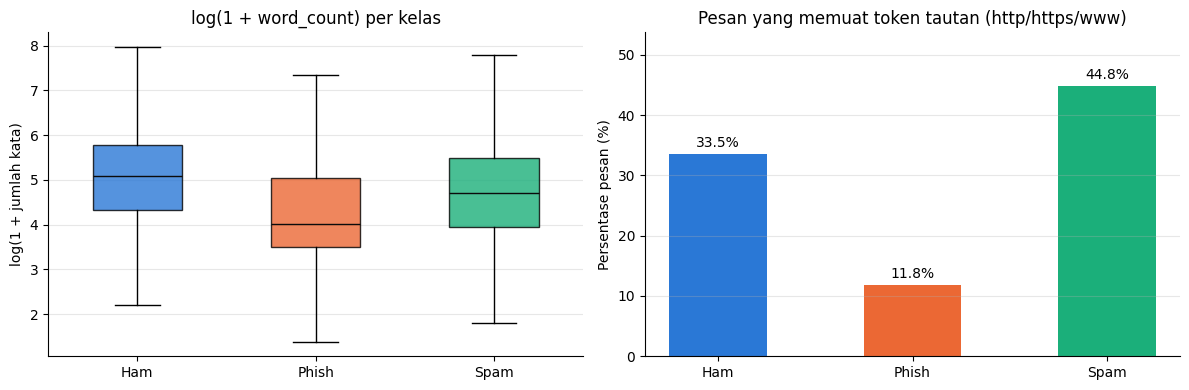

In [8]:
per_class_eda = eda_df.groupby('kelas').agg(
    jumlah_pesan=('word_count', 'size'),
    median_char=('char_count', 'median'),
    median_word=('word_count', 'median'),
    mean_word=('word_count', 'mean'),
    median_special_char=('special_char_count', 'median'),
    persen_ada_token_tautan=('link_token_count', lambda s: (s > 0).mean() * 100),
).reindex(CLASS_ORDER).round(2)
display(per_class_eda)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
box = axes[0].boxplot(
    [np.log1p(eda_df.loc[eda_df['kelas'] == k, 'word_count']) for k in CLASS_ORDER],
    showfliers=False, patch_artist=True, widths=0.5
)
axes[0].set_xticks(range(1, len(CLASS_ORDER) + 1), CLASS_ORDER)
for patch, kelas in zip(box['boxes'], CLASS_ORDER):
    patch.set_facecolor(CLASS_COLORS[kelas])
    patch.set_alpha(0.8)
for median_line in box['medians']:
    median_line.set_color('#0b0b0b')
axes[0].set_title('log(1 + word_count) per kelas')
axes[0].set_ylabel('log(1 + jumlah kata)')

link_rate = per_class_eda['persen_ada_token_tautan']
bars = axes[1].bar(CLASS_ORDER, link_rate.values, color=[CLASS_COLORS[k] for k in CLASS_ORDER], width=0.5)
axes[1].bar_label(bars, fmt='%.1f%%', padding=3)
axes[1].set_title('Pesan yang memuat token tautan (http/https/www)')
axes[1].set_ylabel('Persentase pesan (%)')
axes[1].set_ylim(0, max(link_rate.max() * 1.2, 1))
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### B.6.3 Analisis Multivariat

Sel berikut menghitung korelasi antar fitur dengan dua metode. Korelasi Pearson mengukur hubungan linear dan mudah dipengaruhi nilai ekstrem. Korelasi Spearman memakai urutan nilai, sehingga lebih tahan terhadap pesan yang sangat panjang. Heatmap menampilkan korelasi Spearman.

Korelasi Pearson


,char_count,word_count,link_token_count,special_char_count
char_count,1.00,0.96,0.83,0.08
word_count,0.96,1.00,0.88,0.09
link_token_count,0.83,0.88,1.00,0.04
special_char_count,0.08,0.09,0.04,1.00


Korelasi Spearman


,char_count,word_count,link_token_count,special_char_count
char_count,1.00,0.98,0.21,0.36
word_count,0.98,1.00,0.21,0.45
link_token_count,0.21,0.21,1.00,0.07
special_char_count,0.36,0.45,0.07,1.00


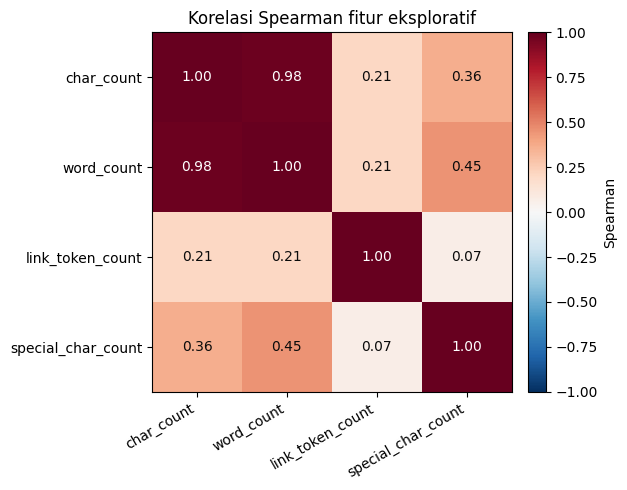

In [9]:
pearson_corr = eda_df[EDA_FEATURES].corr(method='pearson').round(2)
spearman_corr = eda_df[EDA_FEATURES].corr(method='spearman').round(2)
print('Korelasi Pearson')
display(pearson_corr)
print('Korelasi Spearman')
display(spearman_corr)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(spearman_corr.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(EDA_FEATURES)))
ax.set_xticklabels(EDA_FEATURES, rotation=30, ha='right')
ax.set_yticks(range(len(EDA_FEATURES)))
ax.set_yticklabels(EDA_FEATURES)
for i in range(len(EDA_FEATURES)):
    for j in range(len(EDA_FEATURES)):
        value = spearman_corr.values[i, j]
        ax.text(j, i, f'{value:.2f}', ha='center', va='center',
                color='white' if abs(value) > 0.6 else '#0b0b0b')
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='Spearman')
ax.set_title('Korelasi Spearman fitur eksploratif')
plt.tight_layout()
plt.show()

### B.6.4 Sintesis EDA

Tabel berikut merangkum temuan EDA dan keputusan yang dipengaruhi oleh setiap temuan.

In [10]:
class_counts_raw = raw_df['label'].map(LABEL_NAMES).value_counts().reindex(CLASS_ORDER)
imbalance_ratio = class_counts_raw.max() / class_counts_raw.min()
median_words = per_class_eda['median_word']
shortest_class = median_words.idxmin()
link_rate = per_class_eda['persen_ada_token_tautan']

eda_summary_text = f'''
### Temuan EDA dan keputusan yang dipengaruhi

| Temuan | Bukti | Keputusan |
| --- | --- | --- |
| Jumlah pesan antar kelas tidak seimbang | {class_counts_raw.idxmax()} {class_counts_raw.max():,} pesan, {class_counts_raw.idxmin()} {class_counts_raw.min():,} pesan (rasio {imbalance_ratio:.2f} : 1) | Data dibagi secara *stratified*. Evaluasi melaporkan Macro F1 dan Phish Recall, tidak hanya accuracy. |
| Panjang teks sangat condong ke kanan | {int(word_outlier_mask.sum()):,} pencilan IQR ({word_outlier_mask.mean() * 100:.2f}%); pesan terpanjang {int(eda_df["word_count"].max()):,} kata | TF-IDF memakai `sublinear_tf=True` agar kata yang diulang ribuan kali tidak mendominasi bobot. Pesan panjang tetap dipakai karena juga muncul pada email nyata. |
| Panjang pesan berbeda antar kelas | Median jumlah kata: Ham {median_words["Ham"]:.0f}, Phish {median_words["Phish"]:.0f}, Spam {median_words["Spam"]:.0f} | {shortest_class} memiliki pesan terpendek. Pesan pendek memuat sedikit kata, sehingga model memiliki lebih sedikit petunjuk untuk mengenalinya. |
| Tautan tetap tersimpan sebagai kata | Pesan dengan token tautan: Ham {link_rate["Ham"]:.1f}%, Phish {link_rate["Phish"]:.1f}%, Spam {link_rate["Spam"]:.1f}% | Kata `http` dan `www` tidak dihapus pada preprocessing (C.1), sehingga model tetap dapat memakainya. |
| Jumlah karakter dan jumlah kata sangat berkorelasi | Spearman = {spearman_corr.loc["char_count", "word_count"]:.2f}; Pearson = {pearson_corr.loc["char_count", "word_count"]:.2f} | Kedua fitur membawa informasi yang hampir sama. Jika fitur panjang pesan dipakai, satu fitur sudah cukup. |
'''
display(Markdown(eda_summary_text))


### Temuan EDA dan keputusan yang dipengaruhi

| Temuan | Bukti | Keputusan |
| --- | --- | --- |
| Jumlah pesan antar kelas tidak seimbang | Ham 168,455 pesan, Phish 42,845 pesan (rasio 3.93 : 1) | Data dibagi secara *stratified*. Evaluasi melaporkan Macro F1 dan Phish Recall, tidak hanya accuracy. |
| Panjang teks sangat condong ke kanan | 30,385 pencilan IQR (8.31%); pesan terpanjang 1,585,483 kata | TF-IDF memakai `sublinear_tf=True` agar kata yang diulang ribuan kali tidak mendominasi bobot. Pesan panjang tetap dipakai karena juga muncul pada email nyata. |
| Panjang pesan berbeda antar kelas | Median jumlah kata: Ham 161, Phish 55, Spam 110 | Phish memiliki pesan terpendek. Pesan pendek memuat sedikit kata, sehingga model memiliki lebih sedikit petunjuk untuk mengenalinya. |
| Tautan tetap tersimpan sebagai kata | Pesan dengan token tautan: Ham 33.5%, Phish 11.8%, Spam 44.8% | Kata `http` dan `www` tidak dihapus pada preprocessing (C.1), sehingga model tetap dapat memakainya. |
| Jumlah karakter dan jumlah kata sangat berkorelasi | Spearman = 0.98; Pearson = 0.96 | Kedua fitur membawa informasi yang hampir sama. Jika fitur panjang pesan dipakai, satu fitur sudah cukup. |


# C. Preprocessing

## C.1 Langkah Preprocessing

Preprocessing dibuat minimal agar informasi pada teks tidak hilang. Langkah yang dilakukan:

1. menghapus baris yang teks atau labelnya kosong;
2. menghapus label di luar 0, 1, dan 2;
3. mengubah spasi berlebih (spasi ganda, tab, dan baris baru) menjadi satu spasi, lalu menghapus teks yang menjadi kosong;
4. menghapus seluruh teks yang muncul dengan lebih dari satu label, karena label yang benar tidak dapat ditentukan;
5. menghapus duplikat dengan teks dan label yang sama, dan hanya menyimpan kemunculan pertama.

Untuk mendeteksi duplikat, teks dibandingkan dalam huruf kecil (`dedup_key`), sehingga `Hi` dan `hi` dianggap sama. Teks yang dipakai model (`clean_text`) tidak diubah oleh perbandingan ini.

Stemming, lemmatisasi, penghapusan tanda baca, penghapusan URL, dan penghapusan stopword tidak dilakukan. Bagian teks tersebut dapat membantu membedakan spam dan phishing, sehingga hanya dihapus jika eksperimen membuktikan manfaatnya.

In [11]:
# 1-3. Mulai dari text/label mentah, tangani missing value, dan validasi label.
data = raw_df[['text', 'label']].copy()
n_raw = len(data)

data = data.dropna(subset=['text', 'label']).copy()
n_after_missing = len(data)

data = data[data['label'].isin(VALID_LABELS)].copy()
data['label'] = data['label'].astype(int)
n_after_valid_labels = len(data)

# 4-5. Normalisasi whitespace untuk teks model dan hapus teks yang tetap kosong.
data['clean_text'] = (
    data['text']
    .astype(str)
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)
data = data[data['clean_text'].ne('')].copy()
n_after_empty_text = len(data)

# 6-8. Bentuk kunci lowercase hanya untuk deduplikasi exact dan buang seluruh conflict group.
data['dedup_key'] = data['clean_text'].str.lower()
labels_per_key = data.groupby('dedup_key')['label'].nunique()
conflicting_keys = labels_per_key[labels_per_key.gt(1)].index
n_conflicting_groups = len(conflicting_keys)
n_rows_in_conflicts = int(data['dedup_key'].isin(conflicting_keys).sum())

data_without_conflicts = data.loc[~data['dedup_key'].isin(conflicting_keys)].copy()
n_after_conflicts = len(data_without_conflicts)

# 9-10. Sisakan satu perwakilan untuk setiap exact normalized-text key, lalu reset index.
n_same_label_exact_duplicates = int(data_without_conflicts.duplicated(subset=['dedup_key'], keep='first').sum())
df_clean = (
    data_without_conflicts
    .drop_duplicates(subset=['dedup_key'], keep='first')
    [['clean_text', 'label']]
    .rename(columns={'clean_text': 'text'})
    .reset_index(drop=True)
)
n_final = len(df_clean)

assert df_clean['text'].notna().all()
assert df_clean['text'].str.len().gt(0).all()
assert df_clean['label'].isin(VALID_LABELS).all()
assert not df_clean['text'].str.lower().duplicated().any()

print(f'Data bersih siap untuk split berikutnya: {n_final:,} baris')

Data bersih siap untuk split berikutnya: 278,941 baris


## C.2 Data Setelah Preprocessing

Sel berikut menampilkan tiga tabel: jumlah baris yang tersisa setelah setiap langkah, jumlah masalah yang ditemukan, dan distribusi kelas setelah preprocessing.

In [12]:
dataset_flow = pd.DataFrame({
    'tahap': [
        'Data awal',
        'Setelah missing handling',
        'Setelah validasi label',
        'Setelah teks kosong dihapus',
        'Setelah conflict-group removal',
        'Setelah exact normalized-text deduplication'
    ],
    'jumlah_data_tersisa': [
        n_raw, n_after_missing, n_after_valid_labels, n_after_empty_text,
        n_after_conflicts, n_final
    ]
})

preprocessing_issues = pd.DataFrame({
    'masalah': [
        'Missing text',
        'Missing label',
        'Whitespace-only text non-missing',
        'Label tidak valid',
        'Conflicting normalized-text groups',
        'Rows involved in conflicts',
        'Same-label exact normalized-text duplicates setelah conflict removal'
    ],
    'jumlah': [
        int(missing_text_mask.sum()), int(missing_label_mask.sum()),
        int(whitespace_only_mask.sum()), int(invalid_label_mask.sum()),
        n_conflicting_groups, n_rows_in_conflicts, n_same_label_exact_duplicates
    ]
})

clean_class_distribution = (
    df_clean['label']
    .value_counts()
    .sort_index()
    .rename(index=LABEL_NAMES)
    .rename('jumlah')
    .to_frame()
)
clean_class_distribution['persentase'] = (
    clean_class_distribution['jumlah'] / n_final * 100
).round(4)

print('Tabel 1 - Dataset Flow / Records Remaining')
display(dataset_flow)
print('Tabel 2 - Quality Issues Found')
display(preprocessing_issues)
print('Distribusi kelas setelah preprocessing')
display(clean_class_distribution)

Tabel 1 - Dataset Flow / Records Remaining


,tahap,jumlah_data_tersisa
0,Data awal,365448
1,Setelah missing handling,365446
2,Setelah validasi label,365446
3,Setelah teks kosong dihapus,365445
4,Setelah conflict-group removal,365401
5,Setelah exact normalized-text deduplication,278941


Tabel 2 - Quality Issues Found


,masalah,jumlah
0,Missing text,2
1,Missing label,0
2,Whitespace-only text non-missing,1
3,Label tidak valid,0
4,Conflicting normalized-text groups,14
5,Rows involved in conflicts,44
6,Same-label exact normalized-text duplicates se...,86460


Distribusi kelas setelah preprocessing


,jumlah,persentase
label,,
Ham,127740,45.7946
Phish,42838,15.3574
Spam,108363,38.8480


Deduplikasi dilakukan sebelum data dibagi menjadi training dan testing. Tanpa langkah ini, teks yang sama dapat muncul di kedua bagian, sehingga model diuji pada teks yang sudah dipelajarinya (*data leakage*). Deduplikasi ini hanya menghapus teks yang identik. Teks yang hampir sama, misalnya email dari template yang sama, masih dapat tersisa.

### C.3 Persiapan Audit Teks Tanpa Fitur TF-IDF

Teks yang tidak kosong dapat tetap menghasilkan vektor TF-IDF bernilai nol jika tidak ada satu pun katanya yang tercatat dalam vocabulary. Pemeriksaan ini baru dapat dilakukan setelah TF-IDF dilatih pada data training, sehingga dijalankan setelah training pada bagian D.4.

# D. Baseline

Baseline adalah model sederhana yang menjadi titik pembanding bagi model berikutnya. Baseline penelitian ini adalah **TF-IDF unigram + Multinomial Naive Bayes**, dilatih pada data hasil bagian C. Pembagian data dan konfigurasi baseline tidak diubah pada tahap berikutnya, sehingga setiap model kandidat dapat dibandingkan secara adil.

## D.1 Algoritma Baseline

Multinomial Naive Bayes tidak dapat membaca teks secara langsung, sehingga setiap pesan diubah menjadi vektor angka dengan TF-IDF. TF-IDF memberi bobot pada setiap kata: bobot tinggi jika kata sering muncul pada pesan tersebut tetapi jarang muncul pada pesan lain. Multinomial Naive Bayes kemudian menghitung probabilitas setiap kelas berdasarkan bobot kata pada pesan dan memilih kelas dengan probabilitas tertinggi. Model ini dipilih sebagai baseline karena sederhana, cepat dilatih, dan umum dipakai untuk klasifikasi teks. Baseline tidak dioptimalkan.

Sel berikut menetapkan konfigurasi baseline.

In [13]:
import sys
import subprocess

try:
    import sklearn
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'scikit-learn'])
    import sklearn

SPLIT_RANDOM_STATE = 42
TEST_SIZE = 0.20
# Tanpa batas kosakata: seluruh token pada data training menjadi vocabulary.
TFIDF_CONFIG = {
    'lowercase': True,
    'ngram_range': (1, 1),
    'sublinear_tf': True
}
NB_CONFIG = {'alpha': 1.0}

print('Baseline dibekukan: TF-IDF word unigram + MultinomialNB')
print('TF-IDF:', TFIDF_CONFIG)
print('MultinomialNB:', NB_CONFIG)
print(f'Split: {int((1 - TEST_SIZE) * 100)}/{int(TEST_SIZE * 100)}, random_state={SPLIT_RANDOM_STATE}')

Baseline dibekukan: TF-IDF word unigram + MultinomialNB
TF-IDF: {'lowercase': True, 'ngram_range': (1, 1), 'sublinear_tf': True}
MultinomialNB: {'alpha': 1.0}
Split: 80/20, random_state=42


Alasan setiap parameter:

| Komponen | Parameter | Nilai | Alasan |
| --- | --- | --- | --- |
| TF-IDF | `lowercase` | `True` | `Password` dan `password` dianggap kata yang sama. |
| TF-IDF | `ngram_range` | `(1, 1)` | Kata tunggal (*unigram*) adalah representasi teks paling sederhana, sehingga cocok sebagai baseline. |
| TF-IDF | `sublinear_tf` | `True` | Sebagian pesan sangat panjang (B.6). Skala logaritmik mencegah kata yang diulang ribuan kali mendominasi bobot. |
| TF-IDF | Batas kosakata | Tidak ada | Seluruh kata pada data training dipakai, sesuai prinsip C.1 bahwa informasi tidak dihapus tanpa bukti. Multinomial Naive Bayes hanya menyimpan satu nilai per kata untuk setiap kelas, sehingga seluruh kosakata muat di memori. |
| MultinomialNB | `alpha` | `1.0` | *Laplace smoothing*: kata yang belum pernah muncul pada suatu kelas tidak membuat probabilitas kelas tersebut menjadi nol. |
| Split | `test_size`, `stratify`, `random_state` | `0.20`, `y`, `42` | 20% data disisihkan sebagai data testing, proporsi kelas dijaga sama, dan hasil dapat diulang. |

## D.2 Train-Test Split

Data hasil preprocessing dibagi menjadi 80% data training dan 20% data testing dengan `random_state=42`. Pembagian dilakukan secara *stratified*, sehingga proporsi Ham, Phish, dan Spam pada kedua bagian sama dengan proporsi data bersih. Hal ini penting karena Phish adalah kelas terkecil.

Sel berikut menampilkan jumlah data dan distribusi kelas pada data training dan testing.

In [14]:
from sklearn.model_selection import train_test_split

X = df_clean['text']
y = df_clean['label']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=SPLIT_RANDOM_STATE,
    stratify=y
)

def class_distribution_table(labels, nama_set):
    table = labels.value_counts().sort_index().rename(index=LABEL_NAMES).rename('jumlah').to_frame()
    table['persentase'] = (table['jumlah'] / len(labels) * 100).round(4)
    table.index.name = nama_set
    return table

split_summary = pd.DataFrame({
    'set': ['Training', 'Testing'],
    'jumlah_baris': [len(X_train), len(X_test)]
})
display(split_summary)
print('Distribusi kelas training')
display(class_distribution_table(y_train, 'kelas'))
print('Distribusi kelas testing')
display(class_distribution_table(y_test, 'kelas'))

,set,jumlah_baris
0,Training,223152
1,Testing,55789


Distribusi kelas training


,jumlah,persentase
kelas,,
Ham,102192,45.7948
Phish,34270,15.3572
Spam,86690,38.8480


Distribusi kelas testing


,jumlah,persentase
kelas,,
Ham,25548,45.7940
Phish,8568,15.3579
Spam,21673,38.8482


## D.3 TF-IDF

TF-IDF dan Multinomial Naive Bayes digabungkan dalam satu *pipeline*. Pipeline hanya dilatih pada data training, sehingga vocabulary dan bobot IDF dihitung dari data training saja. Data testing hanya diubah menggunakan vocabulary dan bobot tersebut. Jika TF-IDF dilatih pada seluruh data, informasi dari data testing ikut masuk ke model (*data leakage*).

Sel berikut membentuk pipeline tanpa melatihnya.

In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

baseline_model = Pipeline([
    ('tfidf', TfidfVectorizer(**TFIDF_CONFIG)),
    ('classifier', MultinomialNB(**NB_CONFIG))
])

display(baseline_model)

Pipeline(steps=[('tfidf', TfidfVectorizer(sublinear_tf=True)),
                ('classifier', MultinomialNB())])

## D.4 Training

Pipeline dilatih satu kali pada data training dengan konfigurasi D.1. Tidak ada parameter yang disesuaikan berdasarkan hasil testing. Sel berikut juga mencatat ukuran data, seed, konfigurasi, dan ukuran vocabulary agar hasil dapat diulang.

In [16]:
baseline_model.fit(X_train, y_train)

baseline_run_configuration = pd.DataFrame({
    'komponen': [
        'Jumlah data bersih',
        'Jumlah training',
        'Jumlah testing',
        'Train-test split',
        'random_state',
        'TF-IDF',
        'Ukuran vocabulary TF-IDF',
        'MultinomialNB'
    ],
    'konfigurasi': [
        n_final,
        len(X_train),
        len(X_test),
        '80% training / 20% testing dengan stratify=y',
        SPLIT_RANDOM_STATE,
        str(TFIDF_CONFIG),
        f"{len(baseline_model.named_steps['tfidf'].vocabulary_):,} token",
        str(NB_CONFIG)
    ]
})
display(baseline_run_configuration)
print('Training baseline selesai. Belum ada tuning parameter yang dilakukan.')

,komponen,konfigurasi
0,Jumlah data bersih,278941
1,Jumlah training,223152
2,Jumlah testing,55789
3,Train-test split,80% training / 20% testing dengan stratify=y
4,random_state,42
5,TF-IDF,"{'lowercase': True, 'ngram_range': (1, 1), 'su..."
6,Ukuran vocabulary TF-IDF,"721,764 token"
7,MultinomialNB,{'alpha': 1.0}


Training baseline selesai. Belum ada tuning parameter yang dilakukan.


### Audit Teks Tanpa Fitur TF-IDF

Sel berikut menghitung jumlah teks training dan testing yang tidak memiliki satu pun kata dalam vocabulary, lalu menampilkan contohnya. Multinomial Naive Bayes mengklasifikasikan teks seperti ini hanya berdasarkan proporsi kelas pada data training. Teks tersebut tidak dihapus agar evaluasi tetap mencerminkan data asli.

In [17]:
fitted_tfidf = baseline_model.named_steps['tfidf']
X_train_tfidf = fitted_tfidf.transform(X_train)
X_test_tfidf = fitted_tfidf.transform(X_test)

train_zero_positions = np.flatnonzero(X_train_tfidf.getnnz(axis=1) == 0)
test_zero_positions = np.flatnonzero(X_test_tfidf.getnnz(axis=1) == 0)

zero_feature_summary = pd.DataFrame({
    'set': ['Training', 'Testing'],
    'jumlah_dokumen': [len(X_train), len(X_test)],
    'zero_tfidf_features': [len(train_zero_positions), len(test_zero_positions)]
})
zero_feature_summary['persentase'] = (
    zero_feature_summary['zero_tfidf_features'] / zero_feature_summary['jumlah_dokumen'] * 100
).round(4)
display(zero_feature_summary)

def show_zero_feature_examples(texts, labels, positions, nama_set, n=5):
    if len(positions) == 0:
        print(f'Tidak ada dokumen zero-feature pada {nama_set}.')
        return
    examples = pd.DataFrame({
        'label': labels.iloc[positions].to_numpy(),
        'kelas': labels.iloc[positions].map(LABEL_NAMES).to_numpy(),
        'text': texts.iloc[positions].to_numpy()
    }).head(n)
    examples['cuplikan_text'] = examples['text'].str.replace(r'\s+', ' ', regex=True).str.slice(0, 180)
    display(examples[['label', 'kelas', 'cuplikan_text']])

show_zero_feature_examples(X_train, y_train, train_zero_positions, 'training')
show_zero_feature_examples(X_test, y_test, test_zero_positions, 'testing')

,set,jumlah_dokumen,zero_tfidf_features,persentase
0,Training,223152,26,0.0117
1,Testing,55789,57,0.1022


,label,kelas,cuplikan_text
0,2,Spam,p
1,2,Spam,1
2,2,Spam,! ?????? ???? ????? ?? ??? ?????? ! ????? ??? ...
3,2,Spam,a a a a
4,2,Spam,e n o u g h


,label,kelas,cuplikan_text
0,2,Spam,hmvoyxfrbx
1,2,Spam,  ìúíðöj
2,2,Spam,cyhrevx
3,0,Ham,escapenonetext
4,2,Spam,v eaqnuzgrkz ksrorj


## D.5 Hasil Prediksi

Model yang telah dilatih memprediksi kelas setiap pesan pada data testing. Sel berikut menyimpan teks, kelas aktual, kelas prediksi, dan status benar atau salah dalam satu tabel. Tabel ini dipakai pada bagian E dan F.

In [18]:
y_pred = baseline_model.predict(X_test)

results_df = pd.DataFrame({
    'text': X_test.reset_index(drop=True),
    'actual_label': y_test.reset_index(drop=True),
    'predicted_label': y_pred
})
results_df['actual_class'] = results_df['actual_label'].map(LABEL_NAMES)
results_df['predicted_class'] = results_df['predicted_label'].map(LABEL_NAMES)
results_df['correct'] = results_df['actual_label'].eq(results_df['predicted_label'])

def prediction_display(frame):
    shown = frame.copy()
    shown['text'] = shown['text'].str.replace(r'\s+', ' ', regex=True).str.slice(0, 220)
    return shown[['text', 'actual_label', 'actual_class', 'predicted_label', 'predicted_class', 'correct']]

print(f'Hasil prediksi tersedia untuk {len(results_df):,} data testing.')

Hasil prediksi tersedia untuk 55,789 data testing.


# E. Evaluasi Awal

Evaluasi dilakukan pada data testing, yang tidak dipakai saat melatih TF-IDF maupun model. Karena jumlah pesan antar kelas tidak seimbang, accuracy dilaporkan bersama metrik per kelas dan rata-rata macro. Phish Recall dilaporkan tersendiri karena Phish yang tidak terdeteksi adalah kesalahan yang paling berisiko.

## E.1 Metrik dan Hasil

Sel berikut menghitung metrik evaluasi dari label aktual (`y_test`) dan hasil prediksi (`y_pred`). Rata-rata *macro* memberi bobot yang sama pada setiap kelas. Rata-rata *weighted* memberi bobot sesuai jumlah pesan setiap kelas, sehingga lebih dipengaruhi oleh kelas besar.

In [19]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score
)

metric_values = {
    'Accuracy': accuracy_score(y_test, y_pred),
    'Macro Precision': precision_score(y_test, y_pred, average='macro', zero_division=0),
    'Macro Recall': recall_score(y_test, y_pred, average='macro', zero_division=0),
    'Macro F1': f1_score(y_test, y_pred, average='macro', zero_division=0),
    'Weighted Precision': precision_score(y_test, y_pred, average='weighted', zero_division=0),
    'Weighted Recall': recall_score(y_test, y_pred, average='weighted', zero_division=0),
    'Weighted F1': f1_score(y_test, y_pred, average='weighted', zero_division=0)
}

report_dict = classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2],
    target_names=['Ham', 'Phish', 'Spam'],
    output_dict=True,
    zero_division=0
)
per_class_metrics = (
    pd.DataFrame(report_dict).T
    .loc[['Ham', 'Phish', 'Spam'], ['precision', 'recall', 'f1-score', 'support']]
    .rename(columns={'f1-score': 'f1_score'})
)

phish_recall = per_class_metrics.loc['Phish', 'recall']
metric_values['Phish Recall'] = phish_recall

interpretations = {
    'Accuracy': 'Proporsi seluruh prediksi testing yang benar.',
    'Macro Precision': 'Rata-rata precision dengan bobot sama untuk setiap kelas.',
    'Macro Recall': 'Rata-rata recall dengan bobot sama untuk setiap kelas.',
    'Macro F1': 'Keseimbangan precision dan recall dengan bobot sama untuk setiap kelas.',
    'Weighted Precision': 'Precision rata-rata yang mempertimbangkan support tiap kelas.',
    'Weighted Recall': 'Recall rata-rata yang mempertimbangkan support tiap kelas.',
    'Weighted F1': 'F1 rata-rata yang mempertimbangkan support tiap kelas.',
    'Phish Recall': 'Proporsi Phish aktual yang berhasil dikenali sebagai Phish.'
}
evaluation_summary = pd.DataFrame({
    'Metric': list(metric_values.keys()),
    'Result': [round(value, 4) for value in metric_values.values()],
    'Interpretation': [interpretations[name] for name in metric_values]
})

per_class_table = (
    per_class_metrics
    .rename_axis('Class')
    .reset_index()
    .rename(columns={
        'precision': 'Precision',
        'recall': 'Recall',
        'f1_score': 'F1-score',
        'support': 'Support'
    })
)

zero_metrics = evaluation_summary.loc[evaluation_summary['Result'].eq(0), 'Metric'].tolist()
if zero_metrics:
    print(f'Periksa metrik bernilai nol: {zero_metrics}. Nilai tersebut tidak disembunyikan oleh zero_division=0.')

## E.2 Summary Table

Tabel berikut merangkum metrik keseluruhan dan Phish Recall. Kolom *Interpretation* menjelaskan arti setiap metrik.

In [20]:
display(evaluation_summary)

,Metric,Result,Interpretation
0,Accuracy,0.8881,Proporsi seluruh prediksi testing yang benar.
1,Macro Precision,0.9124,Rata-rata precision dengan bobot sama untuk se...
2,Macro Recall,0.8100,Rata-rata recall dengan bobot sama untuk setia...
3,Macro F1,0.8377,Keseimbangan precision dan recall dengan bobot...
4,Weighted Precision,0.8953,Precision rata-rata yang mempertimbangkan supp...
5,Weighted Recall,0.8881,Recall rata-rata yang mempertimbangkan support...
6,Weighted F1,0.8800,F1 rata-rata yang mempertimbangkan support tia...
7,Phish Recall,0.5316,Proporsi Phish aktual yang berhasil dikenali s...


## E.3 Classification Report

Tabel berikut menampilkan Precision, Recall, F1-score, dan Support untuk setiap kelas. *Support* adalah jumlah pesan aktual kelas tersebut pada data testing.

In [21]:
display(per_class_table.round({'Precision': 4, 'Recall': 4, 'F1-score': 4}))

,Class,Precision,Recall,F1-score,Support
0,Ham,0.9094,0.9932,0.9494,25548.0
1,Phish,0.9844,0.5316,0.6904,8568.0
2,Spam,0.8434,0.9051,0.8732,21673.0


## E.4 Confusion Matrix

Confusion matrix menunjukkan jumlah pesan untuk setiap pasangan kelas aktual dan kelas prediksi. Diagonal berisi prediksi benar, sedangkan sel lainnya berisi kesalahan. Tabel di bawahnya merinci kesalahan yang melibatkan Phish.

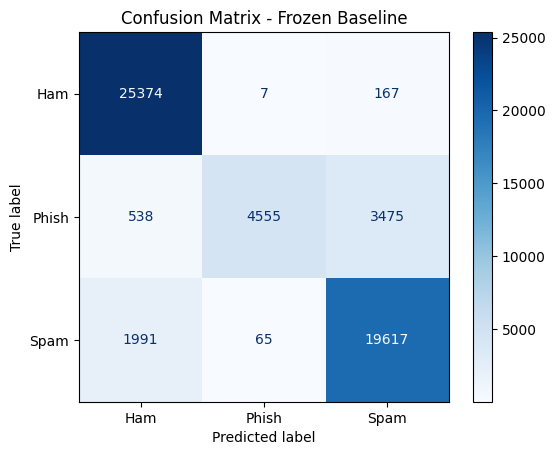

,confusion,jumlah
0,Phish aktual diprediksi Ham,538
1,Phish aktual diprediksi Spam,3475
2,Ham aktual diprediksi Phish,7
3,Spam aktual diprediksi Phish,65


**Interpretasi confusion matrix:** dari 8,568 Phish aktual, 4,555 diprediksi benar sebagai Phish, 538 diprediksi sebagai Ham, dan 3,475 diprediksi sebagai Spam. Kesalahan Ham→Phish berjumlah 7, sedangkan Spam→Phish berjumlah 65.

In [22]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

confusion_counts = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1, 2],
    display_labels=['Ham', 'Phish', 'Spam'],
    values_format='d',
    cmap='Blues'
)
plt.title('Confusion Matrix - Frozen Baseline')
plt.show()

error_counts = pd.DataFrame({
    'confusion': [
        'Phish aktual diprediksi Ham',
        'Phish aktual diprediksi Spam',
        'Ham aktual diprediksi Phish',
        'Spam aktual diprediksi Phish'
    ],
    'jumlah': [
        int(confusion_counts[1, 0]),
        int(confusion_counts[1, 2]),
        int(confusion_counts[0, 1]),
        int(confusion_counts[2, 1])
    ]
})
display(error_counts)

display(Markdown(
    f'**Interpretasi confusion matrix:** dari {int(confusion_counts[1].sum()):,} Phish aktual, '
    f'{int(confusion_counts[1, 1]):,} diprediksi benar sebagai Phish, '
    f'{int(confusion_counts[1, 0]):,} diprediksi sebagai Ham, dan '
    f'{int(confusion_counts[1, 2]):,} diprediksi sebagai Spam. '
    f'Kesalahan Ham→Phish berjumlah {int(confusion_counts[0, 1]):,}, sedangkan '
    f'Spam→Phish berjumlah {int(confusion_counts[2, 1]):,}.'
))

## E.5 Contoh Prediksi

Sel berikut menampilkan tiga kelompok contoh dari data testing: sampel acak, prediksi yang salah, dan prediksi salah yang melibatkan Phish. Teks dipotong hanya untuk tampilan.

In [23]:
sample_predictions = results_df.sample(n=min(10, len(results_df)), random_state=SPLIT_RANDOM_STATE)
print('A. Contoh prediksi testing reproducible')
display(prediction_display(sample_predictions))

incorrect_predictions = results_df.loc[~results_df['correct']].copy()
print(f'Jumlah prediksi salah: {len(incorrect_predictions):,}')
if len(incorrect_predictions):
    incorrect_sample = incorrect_predictions.sample(
        n=min(10, len(incorrect_predictions)),
        random_state=SPLIT_RANDOM_STATE
    )
    print('B. Contoh prediksi salah reproducible')
    display(prediction_display(incorrect_sample))

    phish_related_errors = incorrect_predictions.loc[
        incorrect_predictions['actual_class'].eq('Phish')
        | incorrect_predictions['predicted_class'].eq('Phish')
    ].copy()
    if len(phish_related_errors):
        phish_error_sample = phish_related_errors.sample(
            n=min(10, len(phish_related_errors)),
            random_state=SPLIT_RANDOM_STATE
        )
        print('C. Contoh prediksi salah yang melibatkan Phish')
        display(prediction_display(phish_error_sample))
    else:
        print('Tidak ada prediksi salah yang melibatkan Phish.')
else:
    print('Tidak ada prediksi salah untuk ditampilkan.')

A. Contoh prediksi testing reproducible


,text,actual_label,actual_class,predicted_label,predicted_class,correct
3335,wasp presbytery britches inalienable wolfish s...,2,Spam,2,Spam,True
31660,central bank of nigeria federal republic of ni...,2,Spam,2,Spam,True
971,bd cescapenumber bf eb bescapenumber ee bescap...,2,Spam,2,Spam,True
13167,fyf tax exposure original message rittgers dan...,0,Ham,0,Ham,True
34086,the internet patrol http clicks suretymailings...,0,Ham,0,Ham,True
45718,ëò¡ãòâåðàíõâ´´éò¹åèò§äáèáê´§¡ãø³ò ¤åô¡·õè¹õè ë...,2,Spam,2,Spam,True
20919,isda international swaps derivatives associati...,0,Ham,0,Ham,True
49784,mort239o689six86com protect extended warranty ...,1,Phish,2,Spam,False
20314,¬üär¤£¬o¤ñ¥í¡a ·r¬ü¨ã « d¸o¹l¡i¡i ·í´î­ « ªºª÷...,2,Spam,2,Spam,True
55201,salam for everyone that is happiness to be dis...,2,Spam,2,Spam,True


Jumlah prediksi salah: 6,243
B. Contoh prediksi salah reproducible


,text,actual_label,actual_class,predicted_label,predicted_class,correct
49776,sale software looking inexpensive high quality...,1,Phish,2,Spam,False
18790,hi i sent you an email last week and just want...,2,Spam,0,Ham,False
42696,monocular vivi august stock pick month set bou...,1,Phish,2,Spam,False
16999,b here is your arcamax freesites ezine sponsor...,0,Ham,2,Spam,False
19218,sami_mohammad40 sami_mohammad40caramailcom bur...,1,Phish,2,Spam,False
47044,dear ebay member come attention ebay billing u...,2,Spam,0,Ham,False
23826,breaking biotech news hey thought might want t...,1,Phish,0,Ham,False
39311,makelotsofcashhotmailcom dear friend would lik...,1,Phish,2,Spam,False
48840,check cow http www cowparadehouston com cow la...,0,Ham,2,Spam,False
18519,nationwide pc repairs and upgrades no call out...,2,Spam,0,Ham,False


C. Contoh prediksi salah yang melibatkan Phish


,text,actual_label,actual_class,predicted_label,predicted_class,correct
8339,happy dress next interview c l l e g e e g r e...,1,Phish,2,Spam,False
10394,sunday alpha male plus multiple orgasm supplem...,1,Phish,2,Spam,False
27554,trade counts by 8 : 40 am : trade date na gas ...,0,Ham,1,Phish,False
13667,estela pena dwwetelcomwetelcode purchasing gen...,1,Phish,2,Spam,False
34365,wholesale prices dream weaver mx 2004 ever bou...,1,Phish,2,Spam,False
52992,nelsonkerencentrumcz art sirmadam dearest one ...,1,Phish,2,Spam,False
9450,mortgage approved congratulations mortgage app...,1,Phish,2,Spam,False
4555,whats going get prescri ption sapphire susanne...,1,Phish,2,Spam,False
2447,u robotics analogue wired charset us ascii pro...,1,Phish,2,Spam,False
14174,urgent contact desk dr tom eke e mail dr _ tom...,1,Phish,2,Spam,False


## E.6 Interpretasi Singkat

Sel berikut menuliskan interpretasi berdasarkan metrik dan confusion matrix di atas.

In [24]:
class_f1_range = per_class_metrics['f1_score'].max() - per_class_metrics['f1_score'].min()
phish_support = int(per_class_metrics.loc['Phish', 'support'])
phish_correct = int(confusion_counts[1, 1])
phish_to_ham = int(confusion_counts[1, 0])
phish_to_spam = int(confusion_counts[1, 2])

interpretation_text = f'''
### Interpretasi hasil testing

Baseline memperoleh Accuracy **{metric_values['Accuracy']:.4f}**, Macro F1 **{metric_values['Macro F1']:.4f}**, dan Weighted F1 **{metric_values['Weighted F1']:.4f}**. Weighted F1 lebih dipengaruhi kelas besar (Ham dan Spam), sedangkan Macro F1 memberi bobot yang sama pada ketiga kelas.

Phish Recall adalah **{phish_recall:.4f}**. Dari {phish_support:,} Phish aktual, {phish_correct:,} dikenali sebagai Phish, {phish_to_ham:,} diprediksi sebagai Ham, dan {phish_to_spam:,} diprediksi sebagai Spam. Phish yang diprediksi sebagai Ham masuk ke kotak masuk pengguna. Phish yang diprediksi sebagai Spam tetap tersaring, tetapi tidak memicu peringatan keamanan.

Selisih F1 antara kelas terbaik dan terburuk adalah **{class_f1_range:.4f}**. Oleh karena itu, nilai keseluruhan perlu dibaca bersama hasil per kelas.
'''
display(Markdown(interpretation_text))


### Interpretasi hasil testing

Baseline memperoleh Accuracy **0.8881**, Macro F1 **0.8377**, dan Weighted F1 **0.8800**. Weighted F1 lebih dipengaruhi kelas besar (Ham dan Spam), sedangkan Macro F1 memberi bobot yang sama pada ketiga kelas.

Phish Recall adalah **0.5316**. Dari 8,568 Phish aktual, 4,555 dikenali sebagai Phish, 538 diprediksi sebagai Ham, dan 3,475 diprediksi sebagai Spam. Phish yang diprediksi sebagai Ham masuk ke kotak masuk pengguna. Phish yang diprediksi sebagai Spam tetap tersaring, tetapi tidak memicu peringatan keamanan.

Selisih F1 antara kelas terbaik dan terburuk adalah **0.2590**. Oleh karena itu, nilai keseluruhan perlu dibaca bersama hasil per kelas.


# F. Temuan Awal

Temuan berikut disusun dari hasil audit data, preprocessing, dan evaluasi pada data testing. Dugaan penyebab kesalahan yang belum terbukti ditulis sebagai hipotesis untuk diuji pada tahap berikutnya.

## F.1 Apa yang Berhasil?

Sel berikut merangkum hasil yang berhasil dicapai baseline.

In [25]:
best_class = per_class_metrics['f1_score'].idxmax()
best_class_f1 = per_class_metrics.loc[best_class, 'f1_score']
correct_counts = f"Ham {int(confusion_counts[0, 0]):,}, Phish {int(confusion_counts[1, 1]):,}, dan Spam {int(confusion_counts[2, 2]):,}"
if np.all(np.diag(confusion_counts) > 0):
    correct_note = f'Model menghasilkan prediksi benar pada ketiga kelas: {correct_counts}.'
else:
    correct_note = f'Belum semua kelas memiliki prediksi benar: {correct_counts}.'

success_text = f'''
### Hasil yang berhasil dicapai

- Pipeline memproses {len(raw_df):,} baris data mentah menjadi {len(df_clean):,} pesan yang bersih dan unik. Setiap langkah dapat diulang dengan `random_state={SPLIT_RANDOM_STATE}`.
- TF-IDF dan model dilatih hanya pada {len(X_train):,} pesan training, lalu diuji pada {len(X_test):,} pesan testing yang terpisah. Data testing tidak memengaruhi pelatihan.
- {correct_note}
- Pada data testing, baseline memperoleh Accuracy {metric_values['Accuracy']:.4f}, Macro F1 {metric_values['Macro F1']:.4f}, dan Weighted F1 {metric_values['Weighted F1']:.4f}.
- Kelas dengan F1 tertinggi adalah **{best_class}** (F1 = {best_class_f1:.4f}).
'''
display(Markdown(success_text))


### Hasil yang berhasil dicapai

- Pipeline memproses 365,448 baris data mentah menjadi 278,941 pesan yang bersih dan unik. Setiap langkah dapat diulang dengan `random_state=42`.
- TF-IDF dan model dilatih hanya pada 223,152 pesan training, lalu diuji pada 55,789 pesan testing yang terpisah. Data testing tidak memengaruhi pelatihan.
- Model menghasilkan prediksi benar pada ketiga kelas: Ham 25,374, Phish 4,555, dan Spam 19,617.
- Pada data testing, baseline memperoleh Accuracy 0.8881, Macro F1 0.8377, dan Weighted F1 0.8800.
- Kelas dengan F1 tertinggi adalah **Ham** (F1 = 0.9494).


## F.2 Apa Masalah yang Ditemukan?

Sel berikut merangkum masalah kualitas data dan representasi teks yang ditemukan.

In [26]:
raw_duplicate_count = int(raw_text.duplicated(keep='first').sum())
zero_train_count = int(zero_feature_summary.loc[zero_feature_summary['set'].eq('Training'), 'zero_tfidf_features'].iloc[0])
zero_test_count = int(zero_feature_summary.loc[zero_feature_summary['set'].eq('Testing'), 'zero_tfidf_features'].iloc[0])
zero_total_count = zero_train_count + zero_test_count
if zero_total_count > 0:
    zero_feature_note = (
        f'Sebanyak {zero_total_count:,} teks tidak memiliki satu pun kata dalam vocabulary '
        f'({zero_train_count:,} training, {zero_test_count:,} testing). Contohnya ditampilkan pada audit setelah D.4.'
    )
else:
    zero_feature_note = 'Tidak ada teks yang kehilangan seluruh fiturnya setelah transformasi TF-IDF.'

problem_text = f'''
### Masalah kualitas data dan representasi teks

- Data mentah memuat **{int(missing_text_mask.sum()):,}** teks kosong dan **{int(whitespace_only_mask.sum()):,}** teks yang hanya berisi spasi. Keduanya dihapus.
- Data mentah memuat **{raw_duplicate_count:,}** teks duplikat. Sebanyak **{n_conflicting_groups:,}** kelompok teks muncul dengan label berbeda (**{n_rows_in_conflicts:,}** baris) dan seluruhnya dihapus. Setelah itu, **{n_same_label_exact_duplicates:,}** duplikat dengan label sama dihapus, sehingga tersisa **{len(df_clean):,}** pesan.
- Sebagian teks sangat panjang, rusak, atau tidak berbahasa Inggris (B.5 dan B.6).
- {zero_feature_note}
- Deduplikasi hanya menghapus teks yang identik. Teks yang hampir sama, misalnya email dari template yang sama, masih dapat muncul di data training dan testing sekaligus.
'''
display(Markdown(problem_text))
display(clean_class_distribution.rename(columns={'jumlah': 'Jumlah', 'persentase': 'Persentase (%)'}))


### Masalah kualitas data dan representasi teks

- Data mentah memuat **2** teks kosong dan **1** teks yang hanya berisi spasi. Keduanya dihapus.
- Data mentah memuat **84,498** teks duplikat. Sebanyak **14** kelompok teks muncul dengan label berbeda (**44** baris) dan seluruhnya dihapus. Setelah itu, **86,460** duplikat dengan label sama dihapus, sehingga tersisa **278,941** pesan.
- Sebagian teks sangat panjang, rusak, atau tidak berbahasa Inggris (B.5 dan B.6).
- Sebanyak 83 teks tidak memiliki satu pun kata dalam vocabulary (26 training, 57 testing). Contohnya ditampilkan pada audit setelah D.4.
- Deduplikasi hanya menghapus teks yang identik. Teks yang hampir sama, misalnya email dari template yang sama, masih dapat muncul di data training dan testing sekaligus.


,Jumlah,Persentase (%)
label,,
Ham,127740,45.7946
Phish,42838,15.3574
Spam,108363,38.8480


## F.3 Apa Kelemahan Baseline?

Sel berikut mengurutkan jenis kesalahan pada data testing dari yang paling sering, lalu menampilkan contoh kesalahan Phish → Ham, Phish → Spam, dan Spam → Ham.

In [27]:
results_df['display_text'] = (
    results_df['text'].str.replace(r'\s+', ' ', regex=True).str.slice(0, 220)
)

error_pair_counts = (
    results_df.loc[~results_df['correct']]
    .groupby(['actual_class', 'predicted_class'])
    .size().rename('error_count').reset_index()
    .sort_values('error_count', ascending=False).reset_index(drop=True)
)
phish_to_ham = int(confusion_counts[1, 0])
phish_to_spam = int(confusion_counts[1, 2])
spam_to_ham = int(confusion_counts[2, 0])
phish_recall = metric_values['Phish Recall']
class_recall = per_class_metrics['recall']
lowest_recall_class = class_recall.idxmin()
main_phish_error = 'Spam' if phish_to_spam >= phish_to_ham else 'Ham'

weakness_text = f'''
### Kesalahan yang terukur

- Recall per kelas: Ham {class_recall['Ham']:.4f}, Phish {class_recall['Phish']:.4f}, dan Spam {class_recall['Spam']:.4f}. Kelas yang paling sulit dikenali adalah **{lowest_recall_class}**.
- Sebanyak **{phish_to_spam:,}** Phish diprediksi sebagai Spam dan **{phish_to_ham:,}** diprediksi sebagai Ham. Sebagian besar Phish yang tidak dikenali diprediksi sebagai **{main_phish_error}**.
- Sebanyak **{spam_to_ham:,}** Spam diprediksi sebagai Ham, sehingga pesan tersebut masuk ke kotak masuk pengguna.

Hipotesis penyebab kesalahan, yang akan diuji pada tahap berikutnya:

1. Phish dan Spam memakai banyak kata yang sama, misalnya penawaran produk dan tautan.
2. Unigram tidak menangkap frasa seperti *verify your account*.
3. Jumlah Phish yang lebih sedikit membuat model cenderung memilih kelas yang lebih besar.
'''
display(Markdown(weakness_text))
display(error_pair_counts)

focus_pairs = [('Phish', 'Ham'), ('Phish', 'Spam'), ('Spam', 'Ham')]
for pair_index, (actual_class, predicted_class) in enumerate(focus_pairs):
    pair_examples = results_df.loc[(results_df['actual_class'] == actual_class) & (results_df['predicted_class'] == predicted_class), ['display_text', 'actual_class', 'predicted_class']]
    if not pair_examples.empty:
        display(Markdown(f'#### Contoh {actual_class} → {predicted_class}'))
        display(pair_examples.sample(n=min(3, len(pair_examples)), random_state=SPLIT_RANDOM_STATE + pair_index))


### Kesalahan yang terukur

- Recall per kelas: Ham 0.9932, Phish 0.5316, dan Spam 0.9051. Kelas yang paling sulit dikenali adalah **Phish**.
- Sebanyak **3,475** Phish diprediksi sebagai Spam dan **538** diprediksi sebagai Ham. Sebagian besar Phish yang tidak dikenali diprediksi sebagai **Spam**.
- Sebanyak **1,991** Spam diprediksi sebagai Ham, sehingga pesan tersebut masuk ke kotak masuk pengguna.

Hipotesis penyebab kesalahan, yang akan diuji pada tahap berikutnya:

1. Phish dan Spam memakai banyak kata yang sama, misalnya penawaran produk dan tautan.
2. Unigram tidak menangkap frasa seperti *verify your account*.
3. Jumlah Phish yang lebih sedikit membuat model cenderung memilih kelas yang lebih besar.


,actual_class,predicted_class,error_count
0,Phish,Spam,3475
1,Spam,Ham,1991
2,Phish,Ham,538
3,Ham,Spam,167
4,Spam,Phish,65
5,Ham,Phish,7


#### Contoh Phish → Ham

,display_text,actual_class,predicted_class
50477,qin mrqinwang1954_hongkongo2pl business projec...,Phish,Ham
7907,ilug social everybody gets paid recruiting nee...,Phish,Ham
36193,navy federal credit union keri_godinbrownedu d...,Phish,Ham


#### Contoh Phish → Spam

,display_text,actual_class,predicted_class
28744,garyadams1 garyadams2005yahoocom barclays bank...,Phish,Spam
7471,winning notification de lotto laan van hoornwi...,Phish,Spam
34000,uvfspepperl yhdiana99blycoscom hallo wir haben...,Phish,Spam


#### Contoh Spam → Ham

,display_text,actual_class,predicted_class
48131,commentaires aucun commentaire pour le moment ...,Spam,Ham
34896,china its startling economic growth a breakthr...,Spam,Ham
19682,jim latsis terry keating herrmann news updated...,Spam,Ham


## F.4 Apa yang Perlu Diperbaiki pada Tahap Berikutnya?

Perbaikan berikut diuji sebagai eksperimen terpisah. Baseline tidak diubah, dan setiap eksperimen memakai data bersih serta pembagian data yang sama.

1. **Membandingkan representasi teks.** Multinomial Naive Bayes dirancang untuk frekuensi kata, sedangkan baseline memakai bobot TF-IDF. Eksperimen membandingkan TF-IDF dengan frekuensi kata, serta kata tunggal (*unigram*) dengan pasangan kata (*bigram*).
2. **Menambahkan model kandidat.** Logistic Regression dan model klasifikasi lain dibandingkan dengan baseline untuk mengetahui apakah model yang berbeda mengurangi kesalahan antara Phish dan Spam.
3. **Menangani ketidakseimbangan kelas.** Pengaruh jumlah Phish yang lebih sedikit diuji dengan menyamakan bobot kelas dan dengan *oversampling*, termasuk SMOTE. *Oversampling* hanya diterapkan pada data training.
4. **Memperbaiki strategi evaluasi.** Pemilihan model dan parameter dilakukan dengan *stratified cross-validation* pada data training. Data testing hanya dipakai untuk evaluasi akhir.

Setiap eksperimen melaporkan Macro F1 dan Phish Recall selain accuracy.

### Penutup

Baseline TF-IDF unigram + Multinomial Naive Bayes ditetapkan sebagai titik pembanding. Model pada tahap berikutnya dianggap lebih baik hanya jika hasilnya lebih baik pada data dan strategi evaluasi yang sama.